# Synthetic Benchmark Networks for District Heating Systems
### Working notebook — Methodology II (algorithmic generation of TG/CS benchmark archetypes)


This notebook consolidates the generation pipeline described in **Section 5 (Methodology for
network archetypes generation)**:

1. **District Synthesis** — procedural urban district with centreline street grid and
   consumer substations allocated proportionally to block frontage (`DistrictGenerator`).
2. **Support Street Graph** — `networkx` graph of the street centreline network, with
   `shapely` edge geometries enabling downstream point projection (`StreetGraphBuilder`).
3. **Thermal Network Construction** — orthogonal projection of substations
   and heat source(s) onto the street graph (edge splitting), followed by an approximate
   Steiner Minimal Tree (SMT) spanning all terminals (`ThermalNetworkBuilder`).

Loop augmentation (ring/meshed topologies, Methodology I Rule 3 / Methodology II Step 3
second half) is **not yet implemented** in this notebook — it is the next development
step, to be added as a `MeshAugmenter` class operating on the radial base produced here.

> **Status**: Step 1 (street graph) and Step 2+3 radial (projection + SMT) are implemented
> and tested on medium-scale (100 substations) and large-scale (500 substations) districts.

## 0. Environment setup

In [12]:
import math
import random
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from shapely.geometry import Point, LineString
from networkx.algorithms.approximation import steiner_tree as nx_steiner_tree

## 1. District Synthesis — `DistrictGenerator`

In [13]:
# =====================================================================
# 1. DISTRICT GENERATOR
# =====================================================================
class DistrictGenerator:
    """
    Generates a synthetic urban district grid where roads are modelled as
    single-line centrelines to avoid double-pipe routing artefacts.

    Parameters
    ----------
    width, height    : footprint dimensions [m]
    rows, cols       : number of block rows/columns
    street_width     : uniform street width [m]
    n_substations    : total number of consumer substations
    block_variation  : relative variation of block dimensions (±fraction)
    perturbation     : max jitter on building position along frontage [m]
    seed             : random seed for full reproducibility
    """

    def __init__(self, width=1200, height=800, rows=5, cols=7,
                 street_width=15, n_substations=100,
                 block_variation=0.12, perturbation=5, seed=42):
        self.width           = width
        self.height          = height
        self.rows            = rows
        self.cols            = cols
        self.street_width    = street_width
        self.n_substations   = n_substations
        self.block_variation = block_variation
        self.perturbation    = perturbation
        self.seed            = seed

        random.seed(seed)
        self.blocks       = []
        self.buildings    = []
        self.street_nodes = {}
        self.street_edges = []
        self.street_graph = nx.Graph()

    # ------------------------------------------------------------------
    def random_partition(self, total, n):
        mean   = total / n
        values = [mean * (1 + random.uniform(-self.block_variation,
                                              self.block_variation))
                  for _ in range(n)]
        scale  = total / sum(values)
        values = [v * scale for v in values]
        values[-1] = total - sum(values[:-1])
        return values

    # ------------------------------------------------------------------
    def build_street_grid(self):
        usable_w = self.width  - (self.cols + 1) * self.street_width
        usable_h = self.height - (self.rows  + 1) * self.street_width

        self.block_widths  = self.random_partition(usable_w, self.cols)
        self.block_heights = self.random_partition(usable_h, self.rows)

        # Block boundary coordinates
        self.x = [0]
        for bw in self.block_widths:
            self.x.append(self.x[-1] + self.street_width)
            self.x.append(self.x[-1] + bw)

        self.y = [0]
        for bh in self.block_heights:
            self.y.append(self.y[-1] + self.street_width)
            self.y.append(self.y[-1] + bh)

        # Street centreline coordinates
        cx = [(self.x[i] + self.x[i+1]) / 2 if i+1 < len(self.x)
              else self.x[i] for i in range(0, len(self.x), 2)]
        cy = [(self.y[j] + self.y[j+1]) / 2 if j+1 < len(self.y)
              else self.y[j] for j in range(0, len(self.y), 2)]

        for i, x in enumerate(cx):
            for j, y in enumerate(cy):
                self.street_nodes[(i, j)] = (x, y)

        for i in range(len(cx) - 1):
            for j in range(len(cy)):
                self.street_edges.append(((i, j), (i+1, j)))
        for i in range(len(cx)):
            for j in range(len(cy) - 1):
                self.street_edges.append(((i, j), (i, j+1)))

        for node, pos in self.street_nodes.items():
            self.street_graph.add_node(node, pos=pos)
        for n1, n2 in self.street_edges:
            x1, y1 = self.street_nodes[n1]
            x2, y2 = self.street_nodes[n2]
            self.street_graph.add_edge(n1, n2,
                                       length=abs(x2-x1)+abs(y2-y1))

    # ------------------------------------------------------------------
    def build_blocks(self):
        block_id = 0
        for c in range(self.cols):
            for r in range(self.rows):
                x0 = self.x[2*c + 1]
                y0 = self.y[2*r + 1]
                self.blocks.append({
                    "id": block_id, "x": x0, "y": y0,
                    "col": c, "row": r,
                    "width":  self.block_widths[c],
                    "height": self.block_heights[r],
                    "area":   self.block_widths[c] * self.block_heights[r],
                })
                block_id += 1

    # ------------------------------------------------------------------
    def build_buildings(self):
        building_id = 0
        block_index = 0
        MARGIN  = self.street_width * 0.5
        MIN_GAP = 15.0

        for c in range(self.cols):
            for r in range(self.rows):
                block = self.blocks[block_index]
                x0, y0 = block["x"], block["y"]
                bw, bh  = block["width"], block["height"]

                available = []
                if r < self.rows - 1: available.append("N")
                if r > 0:             available.append("S")
                if c < self.cols - 1: available.append("E")
                if c > 0:             available.append("W")

                if not available:
                    block_index += 1
                    continue

                n = self._allocation[block_index]
                front_lens   = {"N": bw, "S": bw, "E": bh, "W": bh}
                avail_lens   = {s: front_lens[s] for s in available}
                total_len    = sum(avail_lens.values())
                sides_sorted = sorted(avail_lens, key=avail_lens.get,
                                      reverse=True)
                front_counts = {}
                assigned     = 0
                for i, side in enumerate(sides_sorted):
                    if i == len(sides_sorted) - 1:
                        front_counts[side] = n - assigned
                    else:
                        cnt = max(0, round(n * avail_lens[side] / total_len))
                        front_counts[side] = cnt
                        assigned += cnt

                for side, cnt in front_counts.items():
                    if cnt <= 0:
                        continue
                    if side in ("N", "S"):
                        axis_len, axis_start = bw, x0
                        fixed = y0 + bh - MARGIN if side == "N" \
                                else y0 + MARGIN
                    else:
                        axis_len, axis_start = bh, y0
                        fixed = x0 + bw - MARGIN if side == "E" \
                                else x0 + MARGIN

                    spacing = max(axis_len / (cnt + 1), MIN_GAP)
                    for k in range(cnt):
                        pos = axis_start + spacing * (k + 1)
                        pos += random.uniform(-self.perturbation,
                                              self.perturbation)
                        pos = max(axis_start + MIN_GAP,
                                  min(axis_start + axis_len - MIN_GAP, pos))
                        bx, by = (pos, fixed) if side in ("N", "S") \
                                  else (fixed, pos)
                        self.buildings.append({
                            "id": building_id,
                            "x": bx, "y": by,
                            "block": block["id"],
                        })
                        building_id += 1
                block_index += 1

    # ------------------------------------------------------------------
    def generate(self):
        self.build_street_grid()
        self.build_blocks()

        n_blocks    = len(self.blocks)
        avail_cnts  = []
        for idx in range(n_blocks):
            c, r = idx // self.rows, idx % self.rows
            cnt  = sum([r < self.rows-1, r > 0,
                        c < self.cols-1, c > 0])
            avail_cnts.append(max(cnt, 1))

        total_avail = sum(avail_cnts)
        raw         = [self.n_substations * a / total_avail
                       for a in avail_cnts]
        allocation  = [max(1, round(v)) for v in raw]
        diff        = self.n_substations - sum(allocation)
        for i in range(abs(diff)):
            allocation[i % n_blocks] += 1 if diff > 0 else -1
            allocation[i % n_blocks]  = max(0, allocation[i % n_blocks])

        self._allocation = allocation
        self.build_buildings()
        return self

    # ------------------------------------------------------------------
    def plot_district(self, ax=None, show=True):
        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))
        ax.set_facecolor('#AAAAAA')
        colors = ['#F0EEE8', '#EDEAE0', '#F2F0EA', '#EDE8E0']
        for idx, b in enumerate(self.blocks):
            ax.add_patch(patches.Rectangle(
                (b["x"], b["y"]), b["width"], b["height"],
                facecolor=colors[idx % len(colors)],
                edgecolor='none', zorder=1))
        xs = [b["x"] for b in self.buildings]
        ys = [b["y"] for b in self.buildings]
        ax.scatter(xs, ys, color='#CC2200', s=50, marker='s',
                   edgecolors='white', linewidths=0.4, zorder=5,
                   label='Substations')
        ax.set_xlim(-20, self.width+20)
        ax.set_ylim(-20, self.height+20)
        ax.set_title("Synthetic Urban District", fontweight="bold", fontsize=12)
        ax.set_aspect('equal'); ax.axis('off')
        if show:
            plt.tight_layout(); plt.show()

district = DistrictGenerator(
    width=1200, height=800,
    rows=5, cols=7,
    street_width=15,
    n_substations=100,
    block_variation=0.25,
    perturbation=7,
    seed=42,
)
district.generate()
district.plot_district()
### 1.1 Demo — medium-scale district (100 substations)


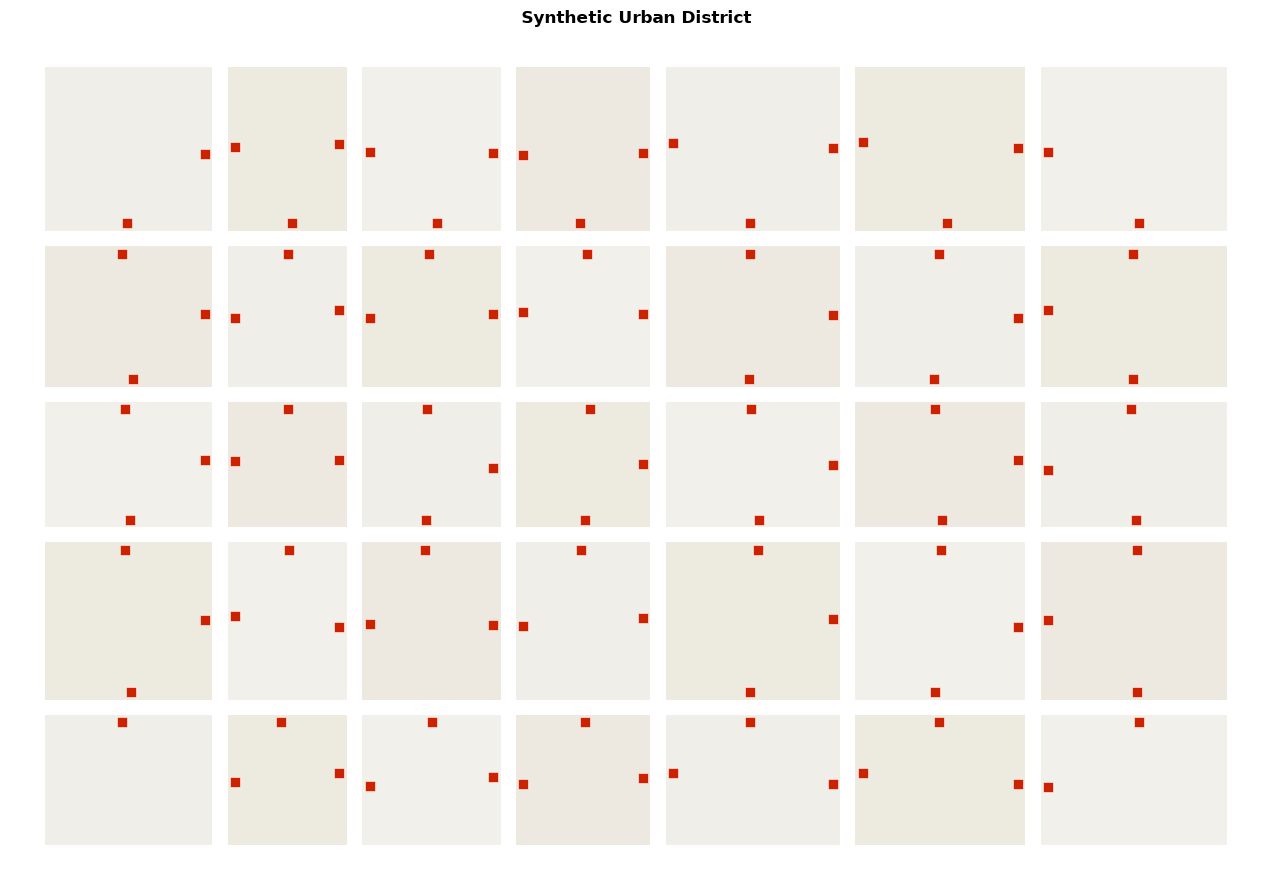

In [14]:
district = DistrictGenerator(
    width=1200, height=800,
    rows=5, cols=7,
    street_width=15,
    n_substations=100,
    block_variation=0.25,
    perturbation=7,
    seed=42,
)
district.generate()
district.plot_district()


## 2. Support Street Graph — `StreetGraphBuilder`

Builds the `networkx.Graph` support structure over the street centreline network:
- **nodes** = street intersections
- **edges** = individual street segments (one per street, no duplicates), each carrying
  `length` and a `shapely.LineString` `geometry` used for orthogonal point projection
  in Step 2/3.

The graph is validated for connectivity, a necessary condition for the Steiner Minimal
Tree computation.

In [15]:
# =====================================================================
# 2. STREET GRAPH BUILDER
# =====================================================================
class StreetGraphBuilder:
    """
    Builds and validates the support street graph starting from an already
    generated DistrictGenerator (after calling .generate()).
    """

    def __init__(self, district: DistrictGenerator):
        if not district.street_nodes:
            raise ValueError(
                "The district has not been generated: call "
                "district.generate() before building the support "
                "street graph."
            )
        self.district = district
        self.graph = nx.Graph()

    # ------------------------------------------------------------------
    def build(self) -> nx.Graph:
        d = self.district

        # --- nodes: street intersections ---
        for node_id, (x, y) in d.street_nodes.items():
            self.graph.add_node(node_id, pos=(x, y), kind="intersection")

        # --- edges: street segments (one per street, no duplicates) ---
        for n1, n2 in d.street_edges:
            x1, y1 = d.street_nodes[n1]
            x2, y2 = d.street_nodes[n2]
            length = math.hypot(x2 - x1, y2 - y1)
            geometry = LineString([(x1, y1), (x2, y2)])
            self.graph.add_edge(n1, n2, length=length, geometry=geometry,
                                 kind="street")

        self._validate()
        return self.graph

    # ------------------------------------------------------------------
    def _validate(self):
        if self.graph.number_of_nodes() == 0:
            raise ValueError("The support street graph is empty.")

        if not nx.is_connected(self.graph):
            n_comp = nx.number_connected_components(self.graph)
            raise ValueError(
                f"The support street graph is not connected "
                f"({n_comp} separate components): the Steiner Minimal Tree "
                f"(Step 3) requires a connected graph. Check the "
                f"grid generation parameters in "
                f"DistrictGenerator (rows, cols, street_width)."
            )

        # degenerate edges (near-zero length) are flagged but not blocking
        zero_len = [
            (u, v) for u, v, l in self.graph.edges(data="length")
            if l is not None and l < 1e-6
        ]
        if zero_len:
            print(f"[WARN] {len(zero_len)} near-zero-length edges detected "
                  f"in the street graph (possible geometric artefact).")

    # ------------------------------------------------------------------
    def stats(self) -> dict:
        lengths = list(nx.get_edge_attributes(self.graph, "length").values())
        return {
            "n_nodes": self.graph.number_of_nodes(),
            "n_edges": self.graph.number_of_edges(),
            "total_length_m": sum(lengths),
            "mean_edge_length_m": sum(lengths) / len(lengths) if lengths else 0.0,
            "is_connected": nx.is_connected(self.graph),
            "n_components": nx.number_connected_components(self.graph),
        }

    # ------------------------------------------------------------------
    def plot(self, ax=None, show=True, with_district=True):
        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))

        if with_district:
            self.district.plot_district(ax=ax, show=False)

        pos = nx.get_node_attributes(self.graph, "pos")
        nx.draw_networkx_edges(self.graph, pos, ax=ax, edge_color="#2266AA",
                                width=1.4, alpha=0.85)
        nx.draw_networkx_nodes(self.graph, pos, ax=ax, node_color="#2266AA",
                                node_size=18, linewidths=0)

        ax.set_title("Support street graph",
                      fontweight="bold", fontsize=12)
        if show:
            plt.tight_layout()
            plt.show()
        return ax

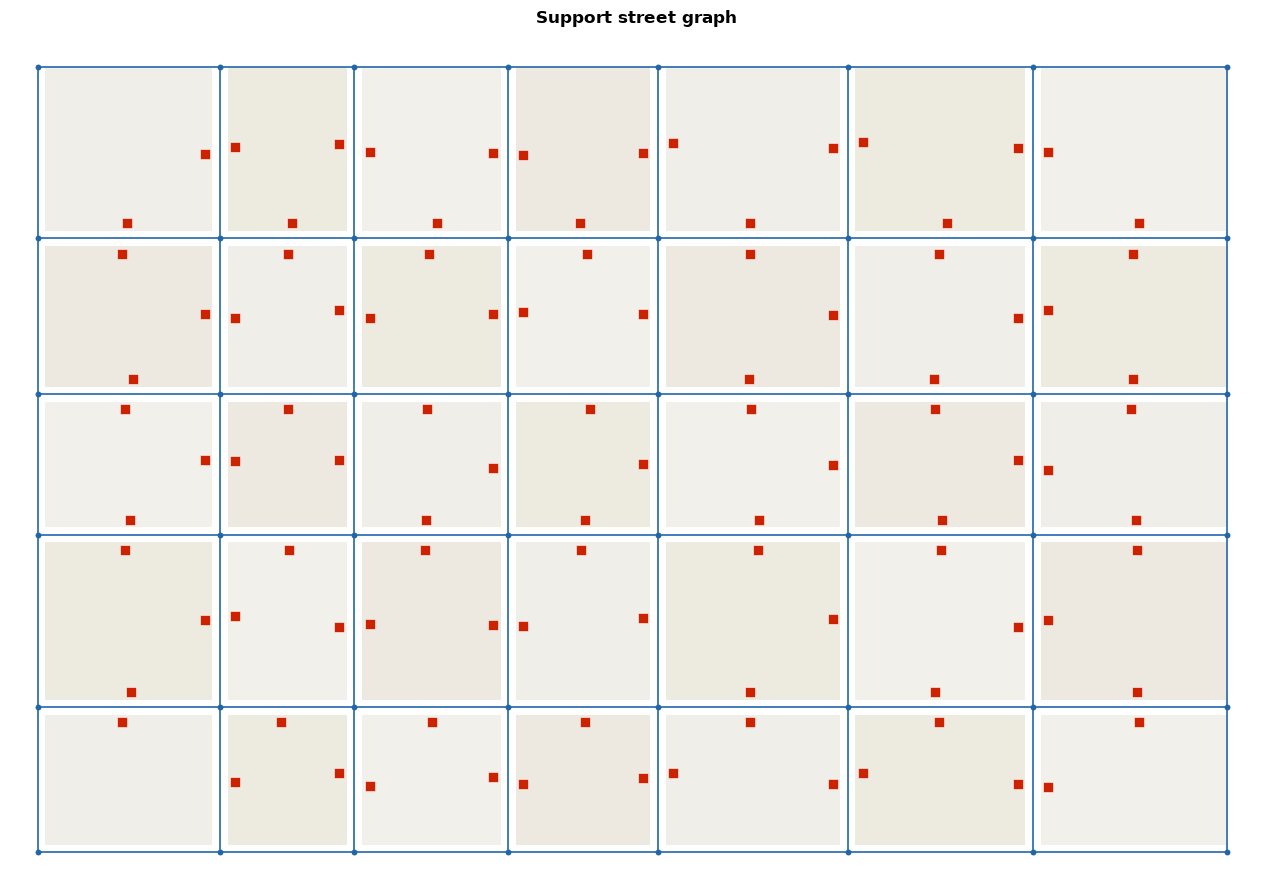

<Axes: title={'center': 'Support street graph'}>

In [16]:
builder_sg = StreetGraphBuilder(district)
street_graph = builder_sg.build()
builder_sg.stats()
builder_sg.plot()

## 3. Thermal Network Construction — `ThermalNetworkBuilder`

In [17]:
import hashlib
import time
import matplotlib.colors as mcolors


# =====================================================================
# 3. THERMAL NETWORK BUILDER
# =====================================================================
class ThermalNetworkBuilder:
    """
    Builds the DHN routing graph G_rou by orthogonally projecting the
    consumer substations and the heat source onto the support street
    graph (edge splitting, Section 2.3), then finds the optimal DHN
    topology G_dhn via the *constrained Steiner tree* algorithm
    (Section 2.4.3 / Appendix A.1, Algorithm 2, Vieth et al. 2025).

    The constrained Steiner tree balances two competing objectives:
      - minimising the total piping length l_sum (investment cost);
      - minimising l_cc, the pipe length from the generator to the
        *critical consumer* (operating cost, via pumping power and
        supply-temperature requirements).
    The trade-off is controlled by the flexibility factor beta >= 1
    (beta=1: lowest l_cc; beta -> large: approaches the unconstrained
    Steiner tree, lowest l_sum).

    Parameters
    ----------
    street_graph : nx.Graph
        Output of ``StreetGraphBuilder.build()``. Nodes carry a ``pos``
        attribute, edges carry ``length`` and a shapely ``geometry``
        (straight ``LineString``), and ``kind="street"``.
    district : DistrictGenerator
        Already-generated district, providing ``district.buildings``
        (list of dicts with ``id``, ``x``, ``y``).
    generator_pos : tuple[float, float]
        (x, y) location of the heat generation unit.
    snap_tol : float
        If a projection falls within this distance [m] of an existing
        street-graph node, the terminal is attached to that node
        directly instead of creating a near-duplicate crossing node.
    """

    #: edge attribute holding a deterministically tie-broken copy of
    #: "length", used only to steer path search away from spurious loops
    #: on (near-)symmetric grids; never used for physical/cost quantities.
    _TB_ATTR = "length_tb"

    def __init__(self, street_graph, district, generator_pos, snap_tol=1.0):
        self.street_graph = street_graph
        self.district = district
        self.generator_pos = generator_pos
        self.snap_tol = snap_tol

        self.rou = None            # G_rou: routing graph (Section 2.3)
        self.dhn = None            # G_dhn: optimal DHN topology (result)
        self.generator_node = None
        self.building_nodes = []   # terminal node ids, one per substation
        self._proj_counter = 0

    # ------------------------------------------------------------------
    # Step 2 (Section 2.3): routing graph via orthogonal projection
    # ------------------------------------------------------------------
    def build_routing_graph(self):
        """Projects every substation and the generator onto the closest
        street edge, splitting it at the projection point, and returns
        the resulting routing graph G_rou."""
        self.rou = self.street_graph.copy()
        self.building_nodes = []

        for b in self.district.buildings:
            node_id = self._connect_point(
                ("sub", b["id"]), b["x"], b["y"], kind="substation")
            self.building_nodes.append(node_id)

        self.generator_node = self._connect_point(
            ("gen", 0), self.generator_pos[0], self.generator_pos[1],
            kind="generator")

        self._assign_tiebreak_weights()

        if not nx.is_connected(self.rou):
            raise ValueError(
                "The routing graph is not connected after projection: "
                "this should not happen if the street graph is connected."
            )
        return self.rou

    # ------------------------------------------------------------------
    def _connect_point(self, node_id, x, y, kind):
        """Orthogonally projects (x, y) onto the closest 'street' edge
        of self.rou, splits that edge at the projection point, and
        attaches node_id to it via a short service-pipe edge."""
        p = Point(x, y)

        best_uv, best_proj, best_dist = None, None, math.inf
        for u, v, data in self.rou.edges(data=True):
            if data.get("kind") != "street":
                continue
            geom = data["geometry"]
            proj_pt = geom.interpolate(geom.project(p))
            d = proj_pt.distance(p)
            if d < best_dist:
                best_uv, best_proj, best_dist = (u, v), proj_pt, d

        if best_uv is None:
            raise RuntimeError("No street edge available to project onto.")

        u, v = best_uv
        u_pos = self.rou.nodes[u]["pos"]
        v_pos = self.rou.nodes[v]["pos"]
        proj_pos = (best_proj.x, best_proj.y)

        # snap to an existing intersection if the projection lands on it
        if math.dist(proj_pos, u_pos) <= self.snap_tol:
            crossing = u
        elif math.dist(proj_pos, v_pos) <= self.snap_tol:
            crossing = v
        else:
            crossing = ("proj", self._proj_counter)
            self._proj_counter += 1
            self.rou.add_node(crossing, pos=proj_pos, kind="crossing")
            self.rou.remove_edge(u, v)
            for a, a_pos, b_, b_pos in ((u, u_pos, crossing, proj_pos),
                                        (crossing, proj_pos, v, v_pos)):
                seg = LineString([a_pos, b_pos])
                self.rou.add_edge(a, b_, length=seg.length,
                                   geometry=seg, kind="street")

        # service pipe: terminal -> crossing point on the street network
        self.rou.add_node(node_id, pos=(x, y), kind=kind)
        service_geom = LineString([(x, y), proj_pos])
        self.rou.add_edge(node_id, crossing,
                           length=max(service_geom.length, 1e-6),
                           geometry=service_geom, kind="service")
        return node_id

    # ------------------------------------------------------------------
    def _assign_tiebreak_weights(self, weight="length", eps=1e-9):
        """Adds a ``length_tb`` edge attribute: the physical length
        perturbed by a vanishingly small (~1e-9 relative), deterministic
        hash-based offset.

        Synthetic/regular street grids (like the one from
        ``DistrictGenerator``) contain many routes of exactly equal
        length. Calling Dijkstra independently for different targets/
        sources can then resolve these ties inconsistently, and merging
        the resulting paths silently turns the intended *tree* into a
        graph with spurious cycles. ``length_tb`` is used everywhere a
        *path is searched for*; every physical quantity (l_max, l_cc,
        l_sum, the constraint checks) keeps using the true ``length``.
        """
        for u, v, d in self.rou.edges(data=True):
            key = f"{u}|{v}" if str(u) < str(v) else f"{v}|{u}"
            tb = int(hashlib.md5(key.encode()).hexdigest(), 16) % 10_000 / 10_000.0
            d[self._TB_ATTR] = d[weight] * (1.0 + eps * tb)

    # ------------------------------------------------------------------
    # helper: materialise a path of G_rou (nodes + edges, with attributes)
    # ------------------------------------------------------------------
    def _add_path(self, graph, path):
        for n in path:
            if n not in graph:
                graph.add_node(n, **self.rou.nodes[n])
        for u, v in zip(path[:-1], path[1:]):
            if not graph.has_edge(u, v):
                graph.add_edge(u, v, **self.rou.edges[u, v])

    # ------------------------------------------------------------------
    # Step 3a (Appendix A.1, Algorithm 1): shortest-path star topology
    # ------------------------------------------------------------------
    def shortest_path_topology(self, weight="length"):
        """Baseline topology: connects every terminal to the generator
        via its own shortest path (Algorithm 1). Guarantees the minimum
        possible l_cc but generally yields a longer l_sum.

        A star-shaped result is, by construction, a *tree* (no loops):
        all paths are extracted from a single Dijkstra run (one
        consistent shortest-path predecessor tree rooted at the
        generator), using the tie-broken weight so that (near-)equal
        length alternatives on regular grids don't get merged into
        spurious cycles."""
        if self.rou is None:
            raise RuntimeError("Call build_routing_graph() first.")

        _, paths = nx.single_source_dijkstra(
            self.rou, self.generator_node, weight=self._TB_ATTR)

        dhn = nx.Graph()
        dhn.add_node(self.generator_node, **self.rou.nodes[self.generator_node])
        for n in self.building_nodes:
            self._add_path(dhn, paths[n])
        return dhn

    # ------------------------------------------------------------------
    # Step 3b (Section 2.4.3, Appendix A.1 Algorithm 2): constrained Steiner
    # ------------------------------------------------------------------
    def constrained_steiner_tree(self, beta=1.25, delta_eps=0.05,
                                  weight="length"):
        """
        Constrained Steiner tree algorithm (Algorithm 2).

        The tree is grown one terminal at a time. At each iteration the
        unconnected terminal r that can be attached to the current tree
        with the *least additional piping length* is selected, provided
        that doing so keeps the resulting generator-to-r distance below
        l_max = beta * l_sp_max (l_sp_max being the longest plain
        shortest-path distance from the generator, i.e. l_cc of
        Algorithm 1). If no admissible shortest connection exists, a
        fallback search (Eq. 4-5) looks for the connection that is
        minimal in additional length while satisfying the constraint,
        using edge weights w(e) = eps*l(e) + (1-eps)*c(e), where c(e) is
        zero for edges already part of the tree and l(e) otherwise; eps
        is increased from delta_eps towards 1 until the constraint is met
        (guaranteed to succeed at eps=1, since l_max >= l_sp_max).

        Parameters
        ----------
        beta : float, >= 1
            Trade-off factor between l_sum (investment) and l_cc
            (operating cost / pressure & temperature control).
        delta_eps : float
            Step size of the fallback weighted search.
        weight : str
            Edge attribute holding the physical pipe length.

        Returns
        -------
        networkx.Graph
            The optimal DHN topology G_dhn.
        """
        if self.rou is None:
            raise RuntimeError("Call build_routing_graph() first.")
        if beta < 1:
            raise ValueError("beta must be >= 1.")

        rou = self.rou
        g = self.generator_node
        terminals = list(self.building_nodes)
        tb = self._TB_ATTR   # tie-broken weight: path *search* only

        # --- l_max = beta * l_sp,max (Section 2.4.3) — true physical length ---
        sp_len, _ = nx.single_source_dijkstra(rou, g, weight=weight)
        l_sp_max = max(sp_len[n] for n in terminals)
        l_max = beta * l_sp_max

        dhn = nx.Graph()
        dhn.add_node(g, **rou.nodes[g])
        unprocessed = set(terminals)

        while unprocessed:
            best_path, best_len = None, math.inf

            # --- greedy pass: cheapest admissible connection (Eq. 3) ---
            for r in unprocessed:
                added_len, path_r = nx.multi_source_dijkstra(
                    rou, sources=set(dhn.nodes), target=r, weight=tb)
                if added_len >= best_len:
                    continue
                dhn_hat = dhn.copy()
                self._add_path(dhn_hat, path_r)
                l_gr = nx.shortest_path_length(dhn_hat, g, r, weight=weight)
                if l_gr <= l_max:
                    best_path, best_len = path_r, added_len

            # --- fallback: weighted search reusing existing pipes (Eq. 4-5) ---
            if best_path is None:
                eps = delta_eps
                while True:
                    def w(u, v, d, _eps=eps):
                        c = 0.0 if dhn.has_edge(u, v) else d[tb]
                        return _eps * d[tb] + (1.0 - _eps) * c

                    w_len, w_paths = nx.single_source_dijkstra(rou, g, weight=w)
                    reachable = {n: w_len[n] for n in unprocessed if n in w_len}
                    r = min(reachable, key=reachable.get)
                    path_r = w_paths[r]

                    dhn_hat = dhn.copy()
                    self._add_path(dhn_hat, path_r)
                    l_gr = nx.shortest_path_length(dhn_hat, g, r, weight=weight)
                    if l_gr <= l_max or eps >= 1.0:
                        best_path = path_r
                        break
                    eps = min(eps + delta_eps, 1.0)

            # --- commit the winning connection ---
            self._add_path(dhn, best_path)
            unprocessed.remove(best_path[-1])

        self.dhn = dhn
        return dhn

    # ------------------------------------------------------------------
    # Step 3c: unconstrained Steiner minimal tree (Kou/Mehlhorn, networkX)
    # ------------------------------------------------------------------
    def steiner_tree_topology(self, weight="length", method="kou"):
        """Wraps networkX's approximate Steiner minimal tree (Kou or
        Mehlhorn) over all terminals + generator, for benchmarking
        against the constrained Steiner tree (Table 1 of the paper).

        ``method`` is only supported by networkX >= 3.2; on older
        versions (where the Kou algorithm is the only option anyway)
        it is silently ignored."""
        if self.rou is None:
            raise RuntimeError("Call build_routing_graph() first.")
        terminals = set(self.building_nodes) | {self.generator_node}
        try:
            return nx_steiner_tree(self.rou, terminals, weight=weight,
                                    method=method)
        except TypeError:
            return nx_steiner_tree(self.rou, terminals, weight=weight)

    # ------------------------------------------------------------------
    # metrics used in Table 1 of the paper: l_sum, l_cc (+ meshed flag)
    # ------------------------------------------------------------------
    def metrics(self, dhn=None, weight="length"):
        dhn = dhn if dhn is not None else self.dhn
        if dhn is None:
            raise RuntimeError("No DHN topology available: run a topology "
                                "search method first or pass one explicitly.")
        l_sum = sum(d[weight] for _, _, d in dhn.edges(data=True))
        l_cc = max(nx.shortest_path_length(dhn, self.generator_node, n,
                                            weight=weight)
                    for n in self.building_nodes)
        return {
            "l_sum_m": l_sum,
            "l_cc_m": l_cc,
            "n_nodes": dhn.number_of_nodes(),
            "n_edges": dhn.number_of_edges(),
            # a genuine Steiner *tree* has edges = nodes - 1; extra edges
            # mean the topology contains real loops (Fig. 3(c)/(d))
            "is_meshed": not nx.is_tree(dhn),
            "n_loops": dhn.number_of_edges() - dhn.number_of_nodes() + 1,
        }

    # ------------------------------------------------------------------
    def plot(self, dhn=None, ax=None, show=True, with_district=True,
              title="Optimal DHN topology"):
        dhn = dhn if dhn is not None else self.dhn
        if dhn is None:
            raise RuntimeError("No DHN topology available to plot.")
        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))

        if with_district:
            self.district.plot_district(ax=ax, show=False)

        pos = nx.get_node_attributes(self.rou, "pos")
        nx.draw_networkx_edges(dhn, pos, ax=ax, edge_color="#CC2200",
                                width=2.2, alpha=0.9)

        sub_nodes = [n for n in dhn.nodes if n in self.building_nodes]
        nx.draw_networkx_nodes(dhn, pos, nodelist=sub_nodes, ax=ax,
                                node_color="#222222", node_size=22,
                                linewidths=0)
        nx.draw_networkx_nodes(dhn, pos, nodelist=[self.generator_node],
                                ax=ax, node_color="#FFB300", node_size=140,
                                edgecolors="black", linewidths=1.0)

        ax.set_title(title, fontweight="bold", fontsize=12)
        if show:
            plt.tight_layout()
            plt.show()
        return ax

    # ------------------------------------------------------------------
    # heat cadastre (Section 2.2): synthetic yearly demand per substation
    # ------------------------------------------------------------------
    def assign_heat_demand(self, seed=1, mu=3.5, sigma=0.6, constant=None):
        """Draws a synthetic yearly heat demand Q [MWh/a] for every
        substation from a log-normal distribution, mimicking the
        right-skewed spread of a real heat cadastre (Section 2.2): many
        small consumers, a few large ones. Stored in ``self.heat_demand``
        keyed by substation node id.

        Parameters
        ----------
        constant : float or None
            If given, every substation gets exactly this demand [MWh/a]
            instead of a random draw.
        """
        if not self.building_nodes:
            raise RuntimeError("Call build_routing_graph() first.")
        if constant is not None:
            self.heat_demand = {n: float(constant) for n in self.building_nodes}
            return self.heat_demand
        rng = random.Random(seed)
        self.heat_demand = {n: rng.lognormvariate(mu, sigma)
                             for n in self.building_nodes}
        return self.heat_demand

    # ------------------------------------------------------------------
    def plot_heat_cadastre(self, ax=None, show=True, n_bins=6,
                            cmap_name="YlOrRd", title="Heat cadastre"):
        """Reproduces Fig. 3(a): buildings colour-coded by yearly heat
        demand Q [MWh/a] (discrete quantile bins, as in the paper's
        legend), plus the generator location."""
        if not getattr(self, "heat_demand", None):
            self.assign_heat_demand()
        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))

        self.district.plot_district(ax=ax, show=False)

        demands = [self.heat_demand[n] for n in self.building_nodes]
        xs = [self.rou.nodes[n]["pos"][0] for n in self.building_nodes]
        ys = [self.rou.nodes[n]["pos"][1] for n in self.building_nodes]

        sorted_d = sorted(demands)
        edges = [sorted_d[round(i * (len(sorted_d) - 1) / n_bins)]
                  for i in range(n_bins + 1)]
        edges[0], edges[-1] = min(demands) - 1e-6, max(demands) + 1e-6
        edges = sorted(set(edges))
        if len(edges) < 2:
            edges = [min(demands) - 1e-6, max(demands) + 1e-6]

        cmap = plt.get_cmap(cmap_name, max(len(edges) - 1, 1))
        norm = mcolors.BoundaryNorm(edges, cmap.N)

        sca = ax.scatter(xs, ys, c=demands, cmap=cmap, norm=norm, s=55,
                          marker="s", edgecolors="white", linewidths=0.4,
                          zorder=6)
        ax.scatter([self.generator_pos[0]], [self.generator_pos[1]],
                    c="#2266AA", s=180, marker="o", edgecolors="black",
                    linewidths=1.0, zorder=7, label="generator")

        cbar = plt.colorbar(sca, ax=ax, boundaries=edges, ticks=edges,
                              fraction=0.035, pad=0.02)
        cbar.ax.tick_params(labelsize=7)
        cbar.set_label("Q in MWh/a", fontsize=9)

        ax.set_xlim(-20, self.district.width + 20)
        ax.set_ylim(-20, self.district.height + 20)
        ax.set_title(title, fontweight="bold", fontsize=12)
        ax.legend(loc="lower right", fontsize=8, framealpha=0.9)
        if show:
            plt.tight_layout()
            plt.show()
        return ax

    # ------------------------------------------------------------------
    # Table 1 replica: every topology-search strategy, timed and scored
    # ------------------------------------------------------------------
    def run_benchmark(self, betas=(1.0, 1.25, 1.5), weight="length"):
        """Runs, in the same order as Table 1 of the paper:
        shortest-path search (Algorithm 1), the constrained Steiner tree
        (Algorithm 2) for each beta in ``betas``, and the unconstrained
        Kou/Mehlhorn Steiner tree (networkX) — each timed with a
        wall-clock t_comp. Returns an ordered list of
        ``(label, graph, metrics_dict)`` and stores it as
        ``self.benchmark_results``. The first constrained-Steiner
        network (lowest beta, most meshed) is kept as ``self.dhn``,
        i.e. the recommended final topology."""
        if self.rou is None:
            raise RuntimeError("Call build_routing_graph() first.")

        results = []

        t0 = time.perf_counter()
        dhn = self.shortest_path_topology(weight=weight)
        t_comp = time.perf_counter() - t0
        results.append(("shortest path search",
                         dhn, {**self.metrics(dhn, weight), "t_comp_s": t_comp}))

        for beta in betas:
            t0 = time.perf_counter()
            dhn = self.constrained_steiner_tree(beta=beta, weight=weight)
            t_comp = time.perf_counter() - t0
            label = f"constrained Steiner (beta={beta:g})"
            results.append((label,
                             dhn, {**self.metrics(dhn, weight), "t_comp_s": t_comp}))

        t0 = time.perf_counter()
        dhn = self.steiner_tree_topology(weight=weight)
        t_comp = time.perf_counter() - t0
        results.append(("Kou (networkX)",
                         dhn, {**self.metrics(dhn, weight), "t_comp_s": t_comp}))

        self.benchmark_results = results
        # recommended output: the most-constrained (most meshed) CS network
        self.dhn = results[1][1]
        return results

    # ------------------------------------------------------------------
    def print_benchmark_table(self, results=None):
        """Prints a Table-1-style summary (l_sum, l_cc, t_comp, meshed?)."""
        results = results if results is not None else getattr(
            self, "benchmark_results", None)
        if results is None:
            raise RuntimeError("Call run_benchmark() first.")

        header = (f"{'Algorithm':32s} {'l_sum [km]':>11s} {'l_cc [km]':>11s} "
                  f"{'t_comp [s]':>11s} {'meshed':>8s} {'loops':>6s}")
        print(header)
        print("-" * len(header))
        for label, _, m in results:
            print(f"{label:32s} {m['l_sum_m']/1000:11.3f} {m['l_cc_m']/1000:11.3f} "
                  f"{m['t_comp_s']:11.3f} {str(m['is_meshed']):>8s} "
                  f"{m['n_loops']:>6d}")

    # ------------------------------------------------------------------
    # Fig. 3 replica: heat cadastre + every resulting topology
    # ------------------------------------------------------------------
    def plot_benchmark(self, results=None, ncols=3):
        """Reproduces Fig. 3 of the paper: one panel per topology
        (heat cadastre first, then every entry of ``results`` in order),
        each showing the street blocks, substations, generator, and the
        DHN pipes of that particular topology."""
        results = results if results is not None else getattr(
            self, "benchmark_results", None)
        if results is None:
            raise RuntimeError("Call run_benchmark() first.")

        n_panels = len(results) + 1  # +1 for the heat cadastre panel
        nrows = math.ceil(n_panels / ncols)
        fig, axes = plt.subplots(nrows, ncols,
                                   figsize=(6.4 * ncols, 5.6 * nrows))
        axes = list(axes.flat) if n_panels > 1 else [axes]

        self.plot_heat_cadastre(ax=axes[0], show=False,
                                  title="(a) heat cadastre")

        letters = "bcdefghijklmnopqrstuvwxyz"
        for i, (label, dhn, m) in enumerate(results):
            letter = letters[i] if i < len(letters) else str(i)
            tag = " [meshed]" if m["is_meshed"] else ""
            self.plot(dhn=dhn, ax=axes[i + 1], show=False,
                      with_district=True,
                      title=f"({letter}) {label}{tag}")

        for ax in axes[n_panels:]:
            ax.axis("off")

        plt.tight_layout()
        plt.show()
        return fig, axes

### 3.1 Demo — full Table 1 / Fig. 3 replica

Reproduces the case-study comparison of Vieth et al. (2025): the heat source is placed at a corner of the district, substations and generator are projected onto the street graph (edge splitting), and every topology-search strategy from the paper is benchmarked (`run_benchmark`) and plotted side by side (`plot_benchmark`), exactly as in Fig. 3:

- **(a)** heat cadastre — synthetic yearly demand `Q` per substation
- **(b)** shortest-path search (Algorithm 1) — star topology, no loops
- **(c)-(e)** constrained Steiner tree (Algorithm 2) for `beta = 1, 1.25, 1.5` — genuinely **meshed** (looped) for the tightest values of `beta`, converging to a pure tree as `beta` grows
- **(f)** unconstrained Steiner tree (Kou, networkX) — lowest `l_sum`, highest `l_cc`

`print_benchmark_table()` reports `l_sum`, `l_cc`, `t_comp` and a `meshed` flag (real cycle detection via `nx.is_tree`) for each variant, mirroring Table 1.

Algorithm                         l_sum [km]   l_cc [km]  t_comp [s]   meshed  loops
------------------------------------------------------------------------------------
shortest path search                   9.779       1.705       0.001    False      0
constrained Steiner (beta=1)           8.613       1.705       1.038     True      4
constrained Steiner (beta=1.25)        8.285       1.705       1.091     True      1
constrained Steiner (beta=1.5)         8.168       2.292       1.140    False      0
Kou (networkX)                         8.160       1.737       0.174    False      0


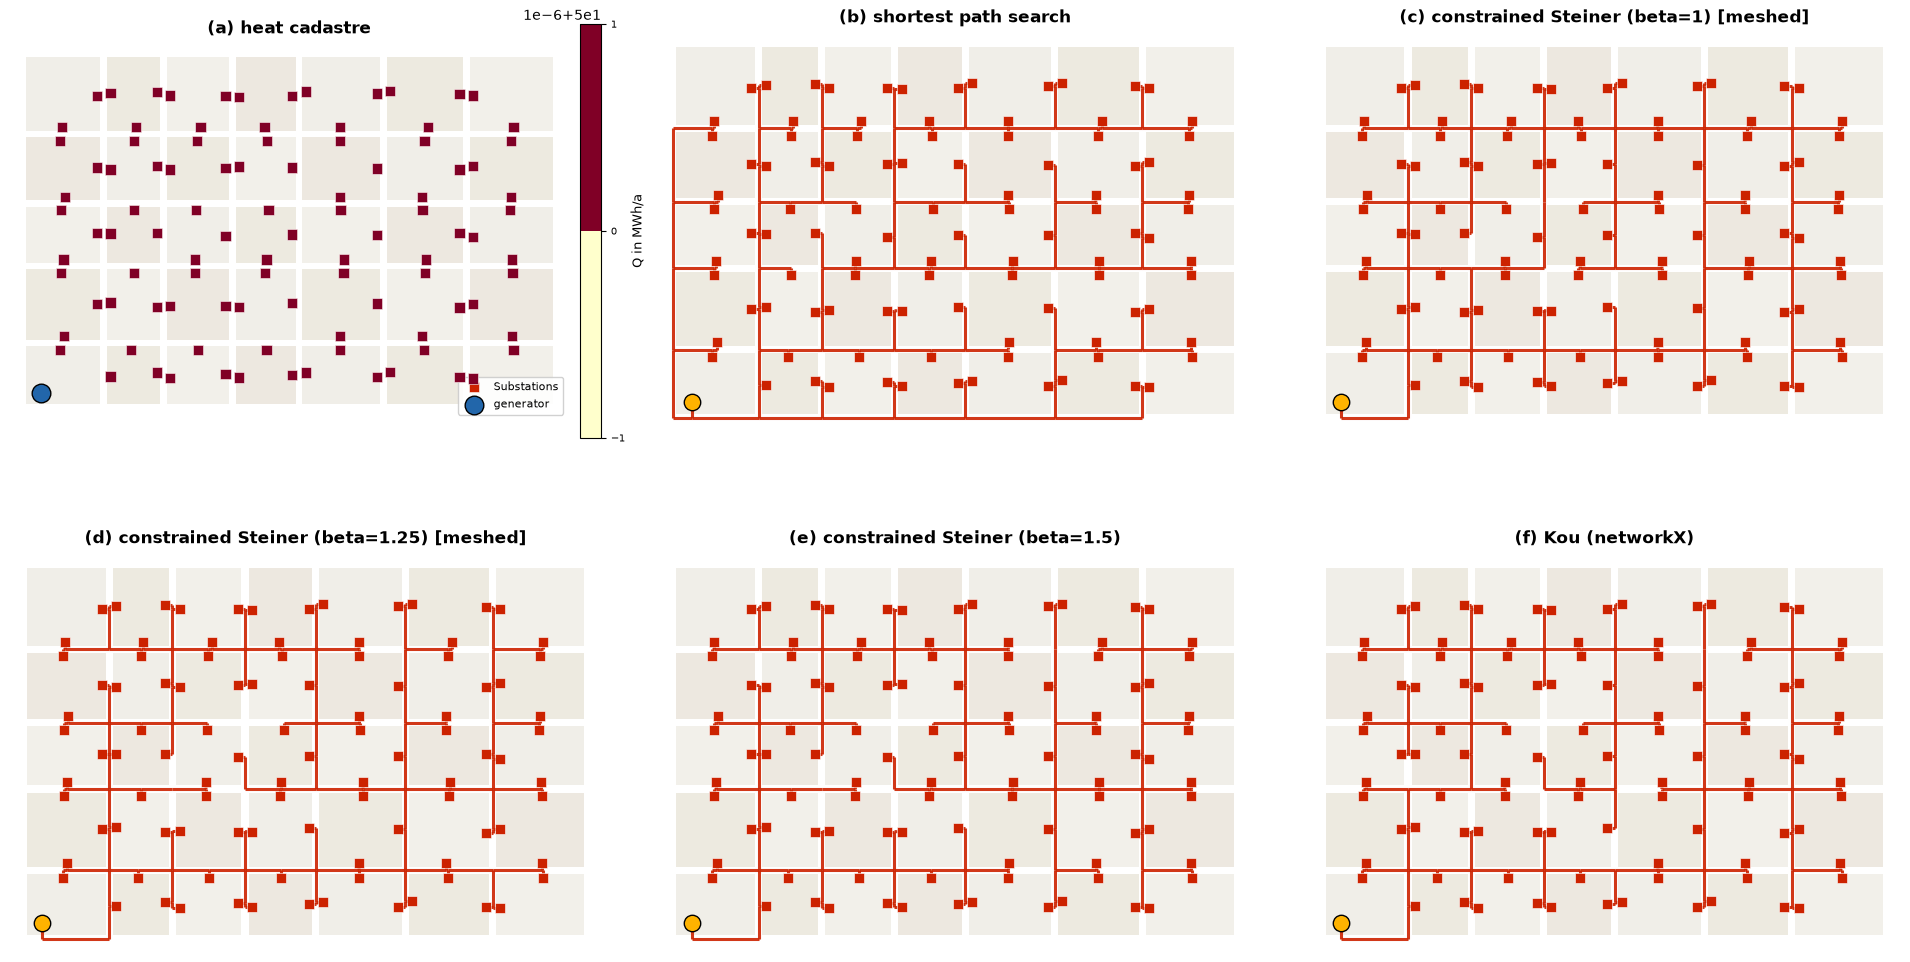

In [18]:
src_block = district.blocks[0 * district.rows + 0]  # col=1, row=0

gen_pos = (src_block["x"] + src_block["width"] / 5,
           src_block["y"] + src_block["height"] / 5)

tnb = ThermalNetworkBuilder(street_graph, district, gen_pos)
tnb.build_routing_graph()

tnb.assign_heat_demand(constant=50.0)

# replicate Table 1: shortest path, constrained Steiner (beta=1, 1.25, 1.5), Kou
results = tnb.run_benchmark(betas=(1.0, 1.25, 1.5))
tnb.print_benchmark_table()

# replicate Fig. 3: heat cadastre + every resulting topology
tnb.plot_benchmark();